In [1]:
print("hello")

hello


In [2]:
import torch
print(torch.cuda.is_available())


# Cette cellule importe PyTorch et vérifie si un GPU compatible CUDA est disponible.
# Le résultat True signifie que le GPU est accessible. False signifie que le programme ne détecte pas de GPU CUDA disponible.

True


In [3]:
!pip install -q ultralytics
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.val(data="VisDrone.yaml", imgsz=640)


# cette cellule réalise trois opérations :
# Installation de la bibliothèque Ultralytics.
# Chargement du modèle YOLOv8n pré-entraîné sur COCO.
# Appel de la validation sur la configuration VisDrone.
# Cet appel permet notamment de télécharger et de préparer automatiquement le dataset VisDrone si celui-ci n'est pas présent.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

WARNING ⚠️ Dataset 'VisDrone.yaml' images not found, missing path '/content/datasets/VisDrone/images/val'
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-val.zip to /content/datasets/VisDrone/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 239.8files/s 4.6s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-test-dev.zip to /content/datasets/VisDrone/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 600.7files/s 5.4s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-train.zip to /content/datasets/VisDrone/VisDr

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fcf9619ef90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [4]:
!ls /content/datasets/VisDrone
!ls /content/datasets/VisDrone/images
!ls /content/datasets/VisDrone/images/train | wc -l



# Cette cellule vérifie la présence du dataset et affiche le nombre d'images disponibles dans le dossier d'entraînement.
# Le dataset contient ici 6 471 images d'entraînement.

images	VisDrone2019-DET-test-dev.zip  VisDrone2019-DET-val.zip
labels	VisDrone2019-DET-train.zip
test  train  val
6471


In [5]:
import random, shutil
from pathlib import Path

root = Path("/content/datasets/VisDrone")
src_img = root / "images/train"
src_lbl = root / "labels/train"
dst = Path("/content/visdrone_sub")
(dst/"images").mkdir(parents=True, exist_ok=True)
(dst/"labels").mkdir(parents=True, exist_ok=True)

imgs = sorted(src_img.glob("*.jpg"))
print(len(imgs), "images trouvées dans train")

random.seed(0)
subset = random.sample(imgs, 2000)

for p in subset:
    shutil.copy(p, dst/"images"/p.name)
    shutil.copy(src_lbl/(p.stem + ".txt"), dst/"labels"/(p.stem + ".txt"))

Path("/content/train_subset.txt").write_text("\n".join(p.name for p in subset))
print(len(list((dst/"images").glob("*.jpg"))), "images copiées")
print(len(list((dst/"labels").glob("*.txt"))), "labels copiés")



# Cette cellule sélectionne aléatoirement 2 000 images parmi les 6 471 images disponibles.
# La fonction random.seed(0) permet de rendre cette sélection reproductible.
# Les images et leurs annotations correspondantes sont ensuite copiées dans un nouveau dossier nommé visdrone_sub.
# Le fichier train_subset.txt conserve la liste des images sélectionnées.
# Cette réduction du dataset permet de diminuer le temps d'entraînement et les besoins en ressources informatiques.

6471 images trouvées dans train
2000 images copiées
2000 labels copiés


In [6]:
from google.colab import drive
drive.mount('/content/drive')
!cd /content && zip -rq visdrone_sub.zip visdrone_sub
!cp /content/visdrone_sub.zip /content/train_subset.txt /content/drive/MyDrive/


# Cette cellule connecte Google Colab à Google Drive.
# elle compresse le sous-ensemble de données dans un fichier ZIP et sauvegarde les fichiers visdrone_sub.zip et train_subset.txt sur Drive.
# Cela permet de conserver les données même lorsque la session Colab est interrompue.

Mounted at /content/drive


In [7]:
yaml_text = """
path: /content/datasets/VisDrone
train: /content/visdrone_sub/images
val: images/val
test: images/test
names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor
"""
open("/content/data.yaml", "w").write(yaml_text)

from ultralytics import YOLO
m = YOLO("yolov8n.pt")
m.train(data="/content/data.yaml", imgsz=640, epochs=30, batch=16, seed=0,
        project="/content/drive/MyDrive/runs", name="e0_640", workers=2)





# ____________________________________________________________________________________________________________________________________________
# Le fichier data.yaml définit les chemins vers les images d'entraînement, de validation et de test, ainsi que les dix catégories d'objets.
# Le modèle YOLOv8n est ensuite entraîné avec les paramètres suivants :

# Modèle : yolov8n.pt.

# *  Résolution : 640 pixels.

# *  Nombre d'époques : 30.

# *  Batch size : 16.

# *  Graine aléatoire : 0.

# *  Nombre de workers : 2.
# Les résultats sont enregistrés dans Google Drive, dans le dossier runs/e0_640.
# Cette expérience constitue notre modèle de référence.
# _____________________________________________________________________________________________________________________________________________

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=e0_640, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fcf942c7d90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [8]:
!ls /content/drive/MyDrive/runs/e0_640
!ls /content/drive/MyDrive/runs/e0_640/weights


# Cette cellule vérifie la présence des fichiers produits par l'entraînement.

# On retrouve notamment :
# -best.pt : meilleurs poids obtenus pendant l'entraînement.
# -last.pt : poids de la dernière époque.
# -results.csv : résultats numériques de chaque époque.
# -results.png : courbes d'apprentissage.
# -confusion_matrix.png : matrice de confusion.
# -BoxPR_curve.png : courbe précision-rappel.
# Les images de prédictions et les annotations de validation.

args.yaml			 results.csv	      val_batch0_labels.jpg
BoxF1_curve.png			 results.png	      val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg     val_batch1_pred.jpg
BoxR_curve.png			 train_batch2500.jpg  val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch2501.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch2502.jpg  weights
labels.jpg			 train_batch2.jpg
best.pt  last.pt


In [10]:
from ultralytics import YOLO
m = YOLO("yolov8n.pt")
m.train(data="/content/data.yaml", imgsz=960, epochs=30, batch=16, seed=0,
        project="/content/drive/MyDrive/runs", name="e1_960", workers=2)



# entraînement E1 avec une résolution de 960 pixels
# Cette cellule reprend le même processus d'entraînement que l'expérience E0.
# La seule modification volontaire est la résolution d'entrée, qui passe de 640 à 960 pixels.
# Les autres paramètres restent identiques :

# Modèle : YOLOv8n.
# Époques : 30.
# Batch size : 16.
# Seed : 0
# Les résultats sont enregistrés dans runs/e1_960-2 pour l'expérience finale.
# Le suffixe -2 provient de l'existence d'un dossier précédent nommé e1_960, créé lors d'un essai interrompu.

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=e1_960-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fced2758360>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [1]:
# teste backup
from google.colab import drive
drive.mount('/content/drive')
!ls /content/drive/MyDrive/runs
!ls /content/drive/MyDrive/runs/e1_960/weights
!wc -l /content/drive/MyDrive/runs/e1_960/results.csv

Mounted at /content/drive
e0_640	e1_960	e1_960-2
wc: /content/drive/MyDrive/runs/e1_960/results.csv: No such file or directory


In [2]:
# Pour verifier le backup de l'entrainement
for d in ["e0_640", "e1_960", "e1_960-2"]:
    print("=====", d)
    !ls /content/drive/MyDrive/runs/{d}
    !ls /content/drive/MyDrive/runs/{d}/weights
    !wc -l /content/drive/MyDrive/runs/{d}/results.csv

===== e0_640
args.yaml			 results.csv	      val_batch0_labels.jpg
BoxF1_curve.png			 results.png	      val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg     val_batch1_pred.jpg
BoxR_curve.png			 train_batch2500.jpg  val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch2501.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch2502.jpg  weights
labels.jpg			 train_batch2.jpg
best.pt  last.pt
31 /content/drive/MyDrive/runs/e0_640/results.csv
===== e1_960
args.yaml   train_batch0.jpg  train_batch2.jpg
labels.jpg  train_batch1.jpg  weights
wc: /content/drive/MyDrive/runs/e1_960/results.csv: No such file or directory
===== e1_960-2
args.yaml			 results.csv	      val_batch0_labels.jpg
BoxF1_curve.png			 results.png	      val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg     val_batch1_pred.jpg
BoxR_curve.png			 train_batch2500.jpg  val_batch2

In [3]:
!grep -E "^(imgsz|epochs|batch|seed|data|name):" /content/drive/MyDrive/runs/e0_640/args.yaml
!grep -E "^(imgsz|epochs|batch|seed|data|name):" /content/drive/MyDrive/runs/e1_960-2/args.yaml

data: /content/data.yaml
epochs: 30
batch: 16
imgsz: 640
name: e0_640
seed: 0
data: /content/data.yaml
epochs: 30
batch: 16
imgsz: 960
name: e1_960-2
seed: 0


In [5]:
# première comparaison
import pandas as pd
base = "/content/drive/MyDrive/runs"
for name in ["e0_640", "e1_960-2"]:
    df = pd.read_csv(f"{base}/{name}/results.csv")
    df.columns = df.columns.str.strip()
    last = df.iloc[-1]
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
    print(name, "| époques :", len(df))
    print("  dernière époque :", {k: round(float(last[k]), 4) for k in
          ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]})
    print("  meilleure époque (mAP50-95) :", int(best["epoch"]), round(float(best["metrics/mAP50-95(B)"]), 4))
    print("  temps d'entraînement (s) :", round(float(last["time"]), 0))

e0_640 | époques : 30
  dernière époque : {'metrics/precision(B)': 0.3666, 'metrics/recall(B)': 0.2857, 'metrics/mAP50(B)': 0.246, 'metrics/mAP50-95(B)': 0.1344}
  meilleure époque (mAP50-95) : 30 0.1344
  temps d'entraînement (s) : 1441.0
e1_960-2 | époques : 30
  dernière époque : {'metrics/precision(B)': 0.4564, 'metrics/recall(B)': 0.3623, 'metrics/mAP50(B)': 0.3452, 'metrics/mAP50-95(B)': 0.1991}
  meilleure époque (mAP50-95) : 30 0.1991
  temps d'entraînement (s) : 2330.0


In [6]:
import pandas as pd
base = "/content/drive/MyDrive/runs"

for name in ["e0_640", "e1_960-2"]:
    print("=====", name)
    !grep -E "^(imgsz|epochs|batch|seed|name):" {base}/{name}/args.yaml
    df = pd.read_csv(f"{base}/{name}/results.csv")
    df.columns = df.columns.str.strip()
    last = df.iloc[-1]
    best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
    print("époques :", len(df), "| temps d'entraînement (s) :", round(float(last["time"])))
    print("dernière époque :", {k.split("/")[1]: round(float(last[k]), 4) for k in
          ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]})
    print("meilleure époque (mAP50-95) :", int(best["epoch"]), round(float(best["metrics/mAP50-95(B)"]), 4))

===== e0_640
epochs: 30
batch: 16
imgsz: 640
name: e0_640
seed: 0
époques : 30 | temps d'entraînement (s) : 1441
dernière époque : {'precision(B)': 0.3666, 'recall(B)': 0.2857, 'mAP50(B)': 0.246, 'mAP50-95(B)': 0.1344}
meilleure époque (mAP50-95) : 30 0.1344
===== e1_960-2
epochs: 30
batch: 16
imgsz: 960
name: e1_960-2
seed: 0
époques : 30 | temps d'entraînement (s) : 2330
dernière époque : {'precision(B)': 0.4564, 'recall(B)': 0.3623, 'mAP50(B)': 0.3452, 'mAP50-95(B)': 0.1991}
meilleure époque (mAP50-95) : 30 0.1991


Notre objectif est maintenant de comparer correctement les deux modèles YOLOv8n :
- E0 : modèle entraîné avec une résolution de 640 × 640.
- E1 : modèle entraîné avec une résolution de 960 × 960.

In [8]:
# -------------Récupérer VisDrone dans Colab----------------------


from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

# Vérification des deux modèles entraînés
e0 = Path("/content/drive/MyDrive/runs/e0_640/weights/best.pt")
e1 = Path("/content/drive/MyDrive/runs/e1_960-2/weights/best.pt")

print("Modèle E0 (640) :", e0.exists())
print("Modèle E1 (960) :", e1.exists())

# Vérification du dataset
dataset = Path("/content/datasets/VisDrone")

print("Dataset VisDrone disponible :", dataset.exists())

if dataset.exists():
    print("Images de validation :",
          len(list((dataset / "images/val").glob("*.jpg"))))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modèle E0 (640) : True
Modèle E1 (960) : True
Dataset VisDrone disponible : False


In [9]:
# -----------récupérer le dataset sans lancer une évaluation inutile---------


!pip install -q ultralytics

from ultralytics.data.utils import check_det_dataset

# Télécharger/préparer VisDrone si nécessaire
dataset_info = check_det_dataset("VisDrone.yaml")

print("Dataset préparé.")
print("Chemin :", dataset_info["path"])
print("Validation :", dataset_info["val"])


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

WARNING ⚠️ Dataset 'VisDrone.yaml' images not found, missing path '/content/datasets/VisDrone/images/val'
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-val.zip to /content/datasets/VisDrone/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 204.2files/s 5.4s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-test-dev.zip to /content/datasets/VisDrone/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 440.8files/s 7.3s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-train.zip to /content/datasets/VisDrone/VisDrone2019-DET-train...: 100% ━━━━━━━━━━━━ 12945/12945 818.0files/s 15.8s
Converting train: ━━━━━━━━━━━━ 6471 1.9Kit/s 3.6s
Converting val: ━━━━━━━━━━━━ 548 1.2Kit/s 0.3

In [10]:
# Préparer le fichier de configuration pour l'évaluation
# Nous allons créer un nouveau fichier data_eval.yaml.
# Il servira à évaluer les modèles sur le même jeu de validation, sans toucher à tes anciens entraînements.




import yaml
from pathlib import Path

data_config = {
    "path": "/content/datasets/VisDrone",
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": [
        "pedestrian",
        "people",
        "bicycle",
        "car",
        "van",
        "truck",
        "tricycle",
        "awning-tricycle",
        "bus",
        "motor"
    ],
    "nc": 10
}

with open("/content/data_eval.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("Fichier créé :", Path("/content/data_eval.yaml").exists())
print("Images de validation :",
      len(list(Path("/content/datasets/VisDrone/images/val").glob("*.jpg"))))


Fichier créé : True
Images de validation : 548


In [11]:
# ------------Évaluer le modèle E0 (640)-----------------




from ultralytics import YOLO

# Charger le modèle entraîné à 640 pixels
model_640 = YOLO(
    "/content/drive/MyDrive/runs/e0_640/weights/best.pt"
)

# Évaluation sur les 548 images de validation
results_640 = model_640.val(
    data="/content/data_eval.yaml",
    imgsz=640,
    project="/content/drive/MyDrive/evaluations",
    name="e0_640_val",
    exist_ok=True
)

print("Évaluation E0 terminée.")


Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2504.5±634.9 MB/s, size: 118.2 KB)
val: Scanning /content/datasets/VisDrone/labels/val... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 1.4Kit/s 0.4s
val: New cache created: /content/datasets/VisDrone/labels/val.cache
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 2.5s/it 1:29
                   all        548      38759      0.367      0.285      0.245      0.134
            pedestrian   

In [12]:
# --------évaluer E1 – 960 × 960--------



from ultralytics import YOLO

model_960 = YOLO(
    "/content/drive/MyDrive/runs/e1_960-2/weights/best.pt"
)

results_960 = model_960.val(
    data="/content/data_eval.yaml",
    imgsz=960,
    max_det=317,
    project="/content/drive/MyDrive/evaluations",
    name="e1_960_val",
    exist_ok=True
)

print("Évaluation E1 terminée.")

Ultralytics 8.4.215 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2367.2±790.8 MB/s, size: 117.0 KB)
val: Scanning /content/datasets/VisDrone/labels/val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 109.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 5.6s/it 3:15
                   all        548      38759      0.458      0.363      0.345      0.199
            pedestrian        520       8844      0.471      0.438      0.411      0.182
                people        482       5125      0.511      0.292      0.301      0.108
               bicycle        364       1287      0.281      0.141      0.106     0.0461
                   car        515      14064      0.632       0.79      0.772      0.521
                   van        421    

In [13]:
# -------Les graphiques comparatifs--------


from pathlib import Path

folders = {
    "E0 - 640": Path("/content/drive/MyDrive/evaluations/e0_640_val"),
    "E1 - 960": Path("/content/drive/MyDrive/evaluations/e1_960_val")
}

for name, folder in folders.items():
    print("\n", name)
    print("Dossier existant :", folder.exists())

    if folder.exists():
        for file in sorted(folder.glob("*.png")):
            print("-", file.name)


 E0 - 640
Dossier existant : True
- BoxF1_curve.png
- BoxPR_curve.png
- BoxP_curve.png
- BoxR_curve.png
- confusion_matrix.png
- confusion_matrix_normalized.png

 E1 - 960
Dossier existant : True
- BoxF1_curve.png
- BoxPR_curve.png
- BoxP_curve.png
- BoxR_curve.png
- confusion_matrix.png
- confusion_matrix_normalized.png


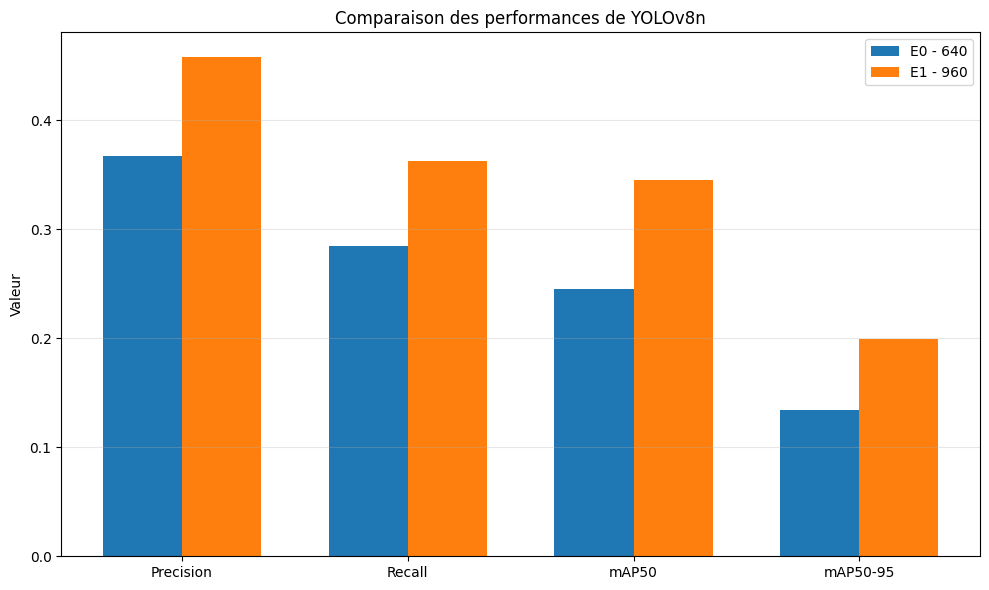

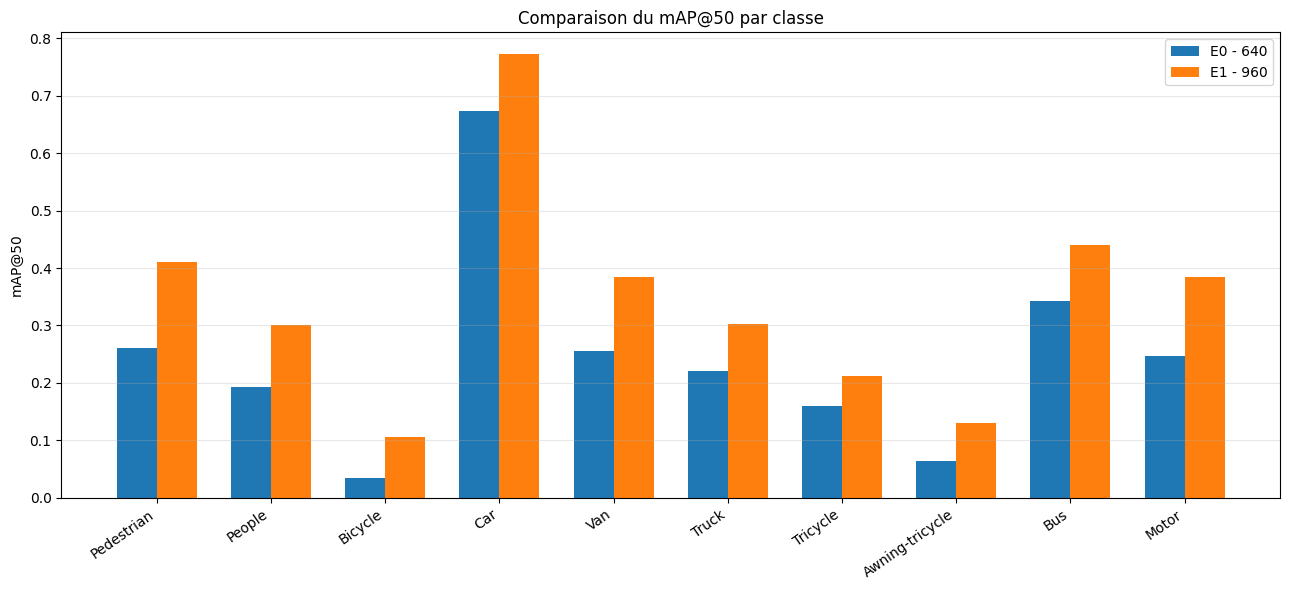

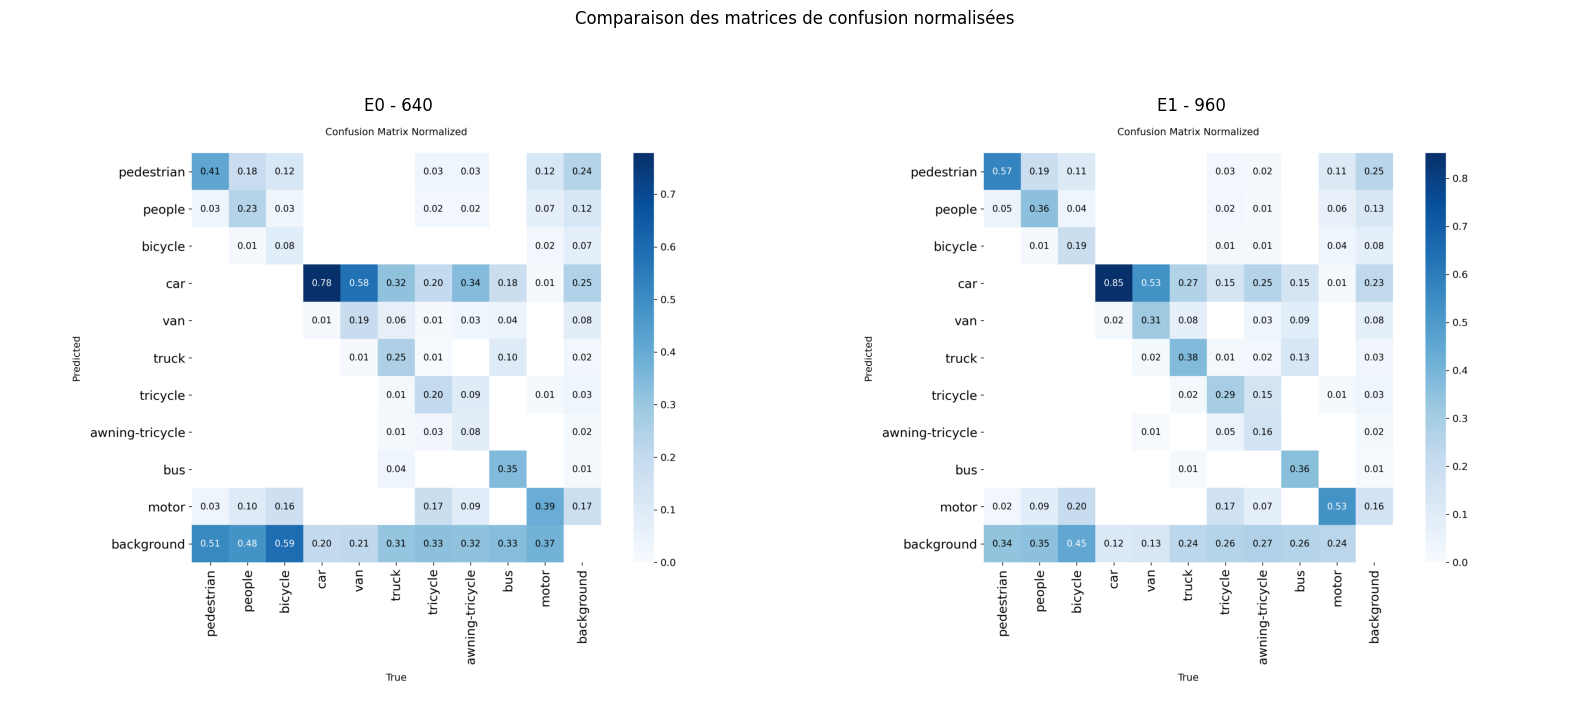

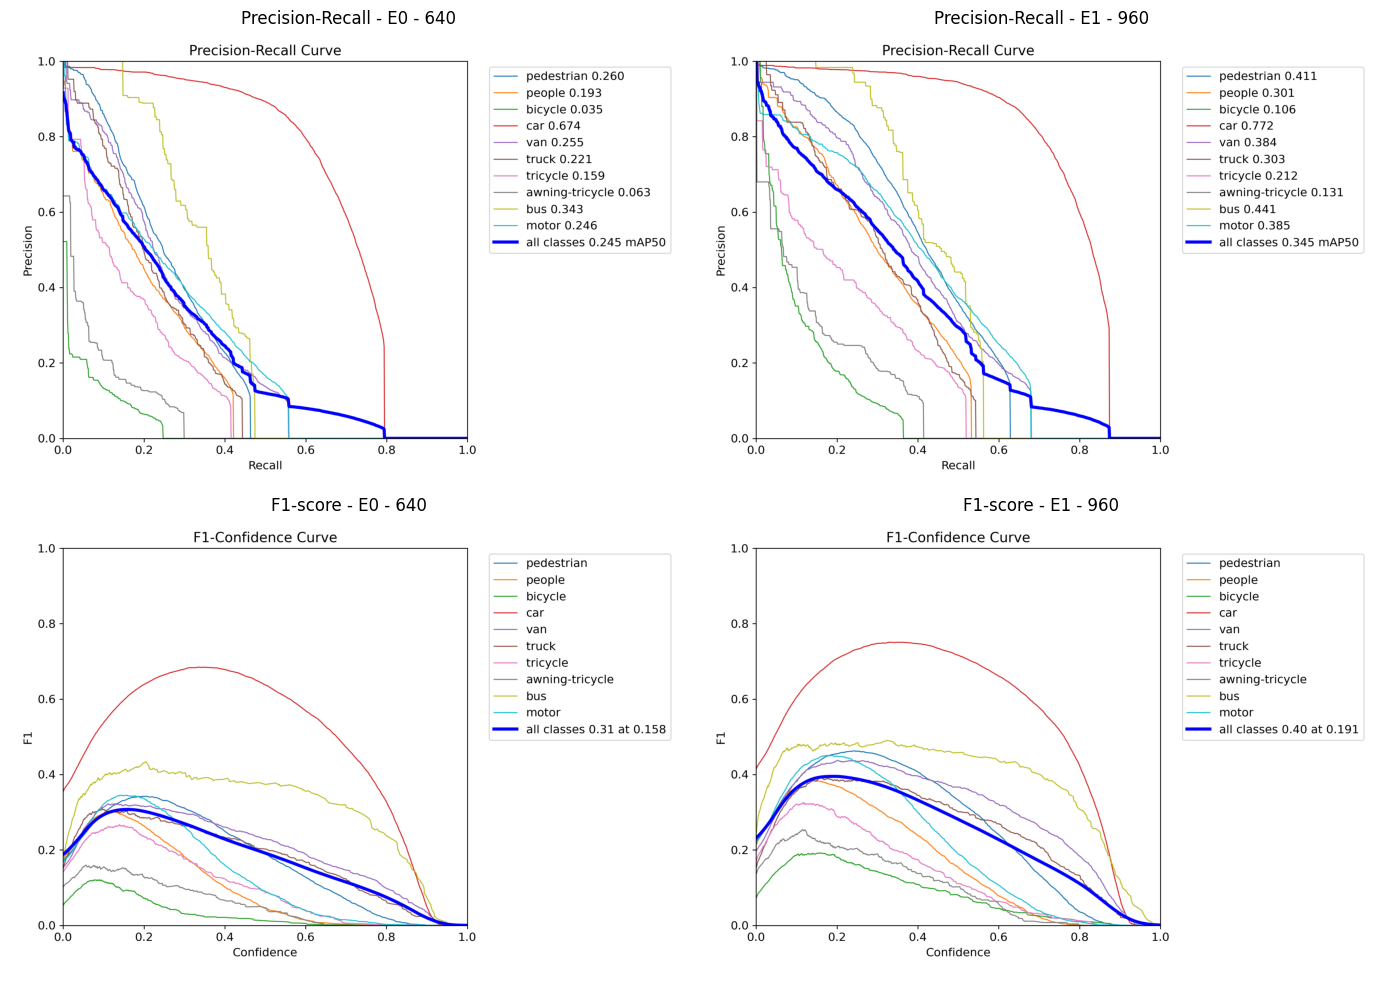

Tous les graphiques sont enregistrés dans : /content/drive/MyDrive/evaluations/comparaison_graphiques


In [14]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path

# Dossiers des évaluations
e0 = Path("/content/drive/MyDrive/evaluations/e0_640_val")
e1 = Path("/content/drive/MyDrive/evaluations/e1_960_val")

# Dossier de sauvegarde
output = Path("/content/drive/MyDrive/evaluations/comparaison_graphiques")
output.mkdir(parents=True, exist_ok=True)

# 1. Comparaison des indicateurs principaux
metrics = ["Precision", "Recall", "mAP50", "mAP50-95"]
values_640 = [0.367, 0.285, 0.245, 0.134]
values_960 = [0.458, 0.363, 0.345, 0.199]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, values_640, width, label="E0 - 640")
plt.bar(x + width/2, values_960, width, label="E1 - 960")

plt.xticks(x, metrics)
plt.ylabel("Valeur")
plt.title("Comparaison des performances de YOLOv8n")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(output / "comparaison_indicateurs.png", dpi=300)
plt.show()

# 2. Comparaison du mAP50 par classe
classes = [
    "Pedestrian", "People", "Bicycle", "Car", "Van",
    "Truck", "Tricycle", "Awning-tricycle", "Bus", "Motor"
]

map_640 = [0.260, 0.193, 0.0349, 0.674, 0.255,
           0.221, 0.159, 0.0631, 0.343, 0.246]

map_960 = [0.411, 0.301, 0.106, 0.772, 0.384,
           0.303, 0.212, 0.131, 0.441, 0.385]

x = np.arange(len(classes))

plt.figure(figsize=(13, 6))
plt.bar(x - width/2, map_640, width, label="E0 - 640")
plt.bar(x + width/2, map_960, width, label="E1 - 960")

plt.xticks(x, classes, rotation=35, ha="right")
plt.ylabel("mAP@50")
plt.title("Comparaison du mAP@50 par classe")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(output / "comparaison_par_classe.png", dpi=300)
plt.show()

# 3. Matrices de confusion normalisées
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, folder, title in [
    (axes[0], e0, "E0 - 640"),
    (axes[1], e1, "E1 - 960")
]:
    img = Image.open(folder / "confusion_matrix_normalized.png")
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("Comparaison des matrices de confusion normalisées")
plt.tight_layout()
plt.savefig(output / "comparaison_matrices.png", dpi=300)
plt.show()

# 4. Comparaison des courbes Precision-Recall et F1
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

curve_files = [
    ("BoxPR_curve.png", "Precision-Recall"),
    ("BoxF1_curve.png", "F1-score")
]

for row, (filename, title) in enumerate(curve_files):
    for col, (folder, label) in enumerate([
        (e0, "E0 - 640"),
        (e1, "E1 - 960")
    ]):
        img = Image.open(folder / filename)
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{title} - {label}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig(output / "comparaison_courbes.png", dpi=300)
plt.show()

print("Tous les graphiques sont enregistrés dans :", output)


In [16]:
# --------compter les objets par taille------------



from pathlib import Path
from PIL import Image
from collections import Counter

images_dir = Path("/content/datasets/VisDrone/images/val")
labels_dir = Path("/content/datasets/VisDrone/labels/val")

counts = Counter()
areas = []

for label_file in labels_dir.glob("*.txt"):
    image_file = images_dir / (label_file.stem + ".jpg")

    if not image_file.exists():
        continue

    with Image.open(image_file) as img:
        image_width, image_height = img.size

    with open(label_file, "r") as f:
        for line in f:
            values = line.strip().split()

            if len(values) < 5:
                continue

            x_center, y_center, width, height = map(float, values[1:5])

            box_width = width * image_width
            box_height = height * image_height
            area = box_width * box_height

            if area < 1024:
                size = "Petit"
            elif area < 9216:
                size = "Moyen"
            else:
                size = "Grand"

            counts[size] += 1
            areas.append(area)

print("Répartition des objets dans le jeu de validation :")
total = sum(counts.values())

for size in ["Petit", "Moyen", "Grand"]:
    number = counts[size]
    percentage = 100 * number / total if total else 0
    print(f"{size}: {number} objets ({percentage:.2f} %)")

print("Total :", total)


Répartition des objets dans le jeu de validation :
Petit: 26586 objets (68.59 %)
Moyen: 11105 objets (28.65 %)
Grand: 1068 objets (2.76 %)
Total : 38759


In [1]:
print('test crash colab limit')

test crash colab limit


In [1]:
import psutil

ram = psutil.virtual_memory()

print("RAM totale :", round(ram.total / 1024**3, 2), "Go")
print("RAM utilisée :", round(ram.used / 1024**3, 2), "Go")
print("RAM disponible :", round(ram.available / 1024**3, 2), "Go")
print("RAM utilisée (%) :", ram.percent, "%")

RAM totale : 12.67 Go
RAM utilisée : 1.16 Go
RAM disponible : 11.22 Go
RAM utilisée (%) : 11.5 %


In [2]:
import gc
import csv
import numpy as np
from pathlib import Path
from PIL import Image
from ultralytics import YOLO

images_dir = Path("/content/datasets/VisDrone/images/val")
labels_dir = Path("/content/datasets/VisDrone/labels/val")

output_dir = Path("/content/drive/MyDrive/evaluations/rappel_par_taille")
output_dir.mkdir(parents=True, exist_ok=True)

images = sorted(images_dir.glob("*.jpg"))

print("Nombre d'images :", len(images))
print("Dossier de sauvegarde :", output_dir)

Nombre d'images : 548
Dossier de sauvegarde : /content/drive/MyDrive/evaluations/rappel_par_taille


In [3]:

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0, x2-x1) * max(0, y2-y1)

    a1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    a2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = a1 + a2 - inter
    return inter / union if union > 0 else 0


def evaluate_size_safe(weights, imgsz, name):
    csv_path = output_dir / f"{name}.csv"

    # Reprendre les images déjà traitées
    done = set()

    if csv_path.exists():
        with open(csv_path, "r") as f:
            done = {row["image"] for row in csv.DictReader(f)}

    model = YOLO(weights)

    sizes = ["Petit", "Moyen", "Grand"]
    totals = {s: 0 for s in sizes}
    matches = {s: 0 for s in sizes}

    # Recalculer les compteurs à partir des images déjà sauvegardées
    for image_path in images:
        if image_path.name not in done:
            continue

        label_path = labels_dir / (image_path.stem + ".txt")
        if not label_path.exists():
            continue

        with open(label_path) as f:
            for line in f:
                v = line.split()
                if len(v) < 5:
                    continue
                with Image.open(image_path) as im:
                    iw, ih = im.size
                area = float(v[3]) * iw * float(v[4]) * ih
                s = "Petit" if area < 1024 else (
                    "Moyen" if area < 9216 else "Grand"
                )
                totals[s] += 1

        # Les correspondances sont sauvegardées dans un second fichier
        match_file = output_dir / f"{name}_matches.csv"
        if match_file.exists():
            with open(match_file) as f:
                for row in csv.DictReader(f):
                    if row["image"] == image_path.name:
                        matches[row["size"]] += int(row["matched"])

    match_file = output_dir / f"{name}_matches.csv"
    write_header = not match_file.exists()

    with open(match_file, "a", newline="") as mf:
        writer = csv.DictWriter(
            mf, fieldnames=["image", "size", "matched"]
        )
        if write_header:
            writer.writeheader()

        for index, image_path in enumerate(images):
            if image_path.name in done:
                continue

            label_path = labels_dir / (image_path.stem + ".txt")

            with Image.open(image_path) as im:
                iw, ih = im.size

            gt_boxes, gt_classes, gt_sizes = [], [], []
            image_totals = {s: 0 for s in sizes}
            image_matches = {s: 0 for s in sizes}

            if label_path.exists():
                with open(label_path) as f:
                    for line in f:
                        v = line.split()
                        if len(v) < 5:
                            continue

                        cls = int(float(v[0]))
                        xc, yc, w, h = map(float, v[1:5])
                        area = w * iw * h * ih

                        s = "Petit" if area < 1024 else (
                            "Moyen" if area < 9216 else "Grand"
                        )

                        box = [
                            (xc-w/2)*iw, (yc-h/2)*ih,
                            (xc+w/2)*iw, (yc+h/2)*ih
                        ]

                        gt_boxes.append(box)
                        gt_classes.append(cls)
                        gt_sizes.append(s)
                        image_totals[s] += 1

            # Prédiction sur une seule image
            result = model.predict(
                source=str(image_path),
                imgsz=imgsz,
                conf=0.25,
                iou=0.7,
                max_det=317,
                device="cpu",
                verbose=False
            )[0]

            pred_boxes = result.boxes.xyxy.cpu().numpy()
            pred_classes = result.boxes.cls.cpu().numpy().astype(int)
            pred_conf = result.boxes.conf.cpu().numpy()

            used = set()

            for p in np.argsort(-pred_conf):
                best_iou, best_gt = 0, None

                for g, gt in enumerate(gt_boxes):
                    if g in used or pred_classes[p] != gt_classes[g]:
                        continue

                    score = calculate_iou(pred_boxes[p], gt)

                    if score > best_iou:
                        best_iou, best_gt = score, g

                if best_gt is not None and best_iou >= 0.5:
                    used.add(best_gt)
                    image_matches[gt_sizes[best_gt]] += 1

            for s in sizes:
                totals[s] += image_totals[s]
                matches[s] += image_matches[s]

                writer.writerow({
                    "image": image_path.name,
                    "size": s,
                    "matched": image_matches[s]
                })

            mf.flush()

            # Enregistrer l'image comme terminée
            with open(csv_path, "a", newline="") as f:
                writer2 = csv.DictWriter(
                    f, fieldnames=["image"]
                )
                if f.tell() == 0:
                    writer2.writeheader()
                writer2.writerow({"image": image_path.name})

            del result, pred_boxes, pred_classes, pred_conf
            gc.collect()

            if (index + 1) % 25 == 0:
                print(f"{name}: {index+1}/{len(images)} images parcourues")

    del model
    gc.collect()

    print(f"\nRésultats {name}")
    for s in sizes:
        recall = matches[s] / totals[s] if totals[s] else 0
        print(f"{s}: {matches[s]}/{totals[s]} = {recall*100:.2f}%")

    return {
        s: matches[s] / totals[s] if totals[s] else 0
        for s in sizes
    }


In [4]:
recall_640 = evaluate_size_safe(
    "/content/drive/MyDrive/runs/e0_640/weights/best.pt",
    640,
    "E0_640"
)

E0_640: 25/548 images parcourues
E0_640: 50/548 images parcourues
E0_640: 75/548 images parcourues
E0_640: 100/548 images parcourues
E0_640: 125/548 images parcourues
E0_640: 150/548 images parcourues
E0_640: 175/548 images parcourues
E0_640: 200/548 images parcourues
E0_640: 225/548 images parcourues
E0_640: 250/548 images parcourues
E0_640: 275/548 images parcourues
E0_640: 300/548 images parcourues
E0_640: 325/548 images parcourues
E0_640: 350/548 images parcourues
E0_640: 375/548 images parcourues
E0_640: 400/548 images parcourues
E0_640: 425/548 images parcourues
E0_640: 450/548 images parcourues
E0_640: 475/548 images parcourues
E0_640: 500/548 images parcourues
E0_640: 525/548 images parcourues

Résultats E0_640
Petit: 6140/26586 = 23.09%
Moyen: 7193/11105 = 64.77%
Grand: 898/1068 = 84.08%


In [7]:

recall_960 = evaluate_size_safe(
    "/content/drive/MyDrive/runs/e1_960-2/weights/best.pt",
    960,
    "E1_960"
)

E1_960: 25/548 images parcourues
E1_960: 50/548 images parcourues
E1_960: 75/548 images parcourues
E1_960: 100/548 images parcourues
E1_960: 125/548 images parcourues
E1_960: 150/548 images parcourues
E1_960: 175/548 images parcourues
E1_960: 200/548 images parcourues
E1_960: 225/548 images parcourues
E1_960: 250/548 images parcourues
E1_960: 275/548 images parcourues
E1_960: 300/548 images parcourues
E1_960: 325/548 images parcourues
E1_960: 350/548 images parcourues
E1_960: 375/548 images parcourues
E1_960: 400/548 images parcourues
E1_960: 425/548 images parcourues
E1_960: 450/548 images parcourues
E1_960: 475/548 images parcourues
E1_960: 500/548 images parcourues
E1_960: 525/548 images parcourues

Résultats E1_960
Petit: 9134/26586 = 34.36%
Moyen: 8179/11105 = 73.65%
Grand: 936/1068 = 87.64%


In [ ]:
# ####################################

# Calculer le rappel par taille pour E0 et E1
# Nous allons utiliser les mêmes conditions pour les deux modèles :
# - Seuil de confiance : 0,25.
# - Seuil IoU : 0,50 pour considérer une détection comme correcte.
# - Correspondance de classe obligatoire.
# - Même jeu de validation : 548 images.


# Cette méthode calcule le rappel par taille à un seuil de confiance fixé à 0,25.
# Ce n'est pas un mAP par taille : nous ne devons pas confondre les deux indicateurs.
#  Elle utilise une correspondance individuelle entre les prédictions et les annotations.

# ##########################################


# import numpy as np
# from pathlib import Path
# from PIL import Image
# from ultralytics import YOLO

# # Chemins
# images_dir = Path("/content/datasets/VisDrone/images/val")
# labels_dir = Path("/content/datasets/VisDrone/labels/val")

# images = sorted(images_dir.glob("*.jpg"))

# # Seuils
# CONF = 0.25
# IOU_THRESHOLD = 0.50
# MAX_DET = 317

# # Calcul de l'IoU entre deux boîtes
# def calculate_iou(box1, box2):
#     x1 = max(box1[0], box2[0])
#     y1 = max(box1[1], box2[1])
#     x2 = min(box1[2], box2[2])
#     y2 = min(box1[3], box2[3])

#     intersection = max(0, x2-x1) * max(0, y2-y1)

#     area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
#     area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

#     union = area1 + area2 - intersection

#     return intersection / union if union > 0 else 0


# def evaluate_by_size(weights, imgsz):
#     model = YOLO(weights)

#     sizes = ["Petit", "Moyen", "Grand"]
#     total_gt = {s: 0 for s in sizes}
#     matched_gt = {s: 0 for s in sizes}

#     predictions = model.predict(
#         source=[str(p) for p in images],
#         imgsz=imgsz,
#         conf=CONF,
#         iou=0.7,
#         max_det=MAX_DET,
#         device="cpu",
#         stream=True,
#         verbose=False
#     )

#     for image_path, result in zip(images, predictions):

#         with Image.open(image_path) as im:
#             img_w, img_h = im.size

#         # Charger les annotations
#         gt_boxes = []
#         gt_classes = []
#         gt_sizes = []

#         label_path = labels_dir / (image_path.stem + ".txt")

#         if label_path.exists():
#             with open(label_path, "r") as f:
#                 for line in f:
#                     values = line.strip().split()

#                     if len(values) < 5:
#                         continue

#                     cls = int(float(values[0]))
#                     xc, yc, w, h = map(float, values[1:5])

#                     bw = w * img_w
#                     bh = h * img_h
#                     area = bw * bh

#                     if area < 1024:
#                         size = "Petit"
#                     elif area < 9216:
#                         size = "Moyen"
#                     else:
#                         size = "Grand"

#                     box = [
#                         (xc - w/2) * img_w,
#                         (yc - h/2) * img_h,
#                         (xc + w/2) * img_w,
#                         (yc + h/2) * img_h
#                     ]

#                     gt_boxes.append(box)
#                     gt_classes.append(cls)
#                     gt_sizes.append(size)
#                     total_gt[size] += 1

#         # Récupérer les prédictions
#         pred_boxes = result.boxes.xyxy.cpu().numpy()
#         pred_classes = result.boxes.cls.cpu().numpy().astype(int)
#         pred_conf = result.boxes.conf.cpu().numpy()

#         # Traiter les prédictions de la plus forte confiance
#         order = np.argsort(-pred_conf)
#         used_gt = set()

#         for p in order:
#             best_iou = 0
#             best_gt = None

#             for g in range(len(gt_boxes)):
#                 if g in used_gt:
#                     continue

#                 if pred_classes[p] != gt_classes[g]:
#                     continue

#                 iou_value = calculate_iou(
#                     pred_boxes[p], gt_boxes[g]
#                 )

#                 if iou_value > best_iou:
#                     best_iou = iou_value
#                     best_gt = g

#             if best_gt is not None and best_iou >= IOU_THRESHOLD:
#                 used_gt.add(best_gt)
#                 matched_gt[gt_sizes[best_gt]] += 1

#     print(f"\nRésultats pour imgsz={imgsz}")

#     recalls = {}

#     for size in sizes:
#         recall = (
#             matched_gt[size] / total_gt[size]
#             if total_gt[size] else 0
#         )

#         recalls[size] = recall

#         print(
#             f"{size}: {matched_gt[size]}/{total_gt[size]} "
#             f"objets détectés - Recall = {recall:.4f} "
#             f"({recall*100:.2f} %)"
#         )

#     return recalls


# # Évaluation des deux modèles
# recall_640 = evaluate_by_size(
#     "/content/drive/MyDrive/runs/e0_640/weights/best.pt",
#     640
# )

# recall_960 = evaluate_by_size(
#     "/content/drive/MyDrive/runs/e1_960-2/weights/best.pt",
#     960
# )

# # Tableau comparatif
# print("\n===== COMPARAISON FINALE =====")

# for size in ["Petit", "Moyen", "Grand"]:
#     r0 = recall_640[size] * 100
#     r1 = recall_960[size] * 100

#     print(
#         f"{size}: E0={r0:.2f}% | "
#         f"E1={r1:.2f}% | "
#         f"Écart={r1-r0:+.2f} points"
#     )
